# Offline

In [1]:

G1 = generate_gp_ts(
    n=2000,
    t0=1000,
    c_pre=0,
    c_post=0.5
)

#G1 = (G1-G1.mean())/G1.std()

G2 = generate_gp_ts(
    n=2000,
    t0=1000,
    c_pre=0,
    c_post=10,
    length_scale=10
)

#G2 = (G2-G2.mean())/G2.std()
g =  G1+G2

# plot the two GPs and their sum
plt.figure(figsize=(12, 6))
plt.plot(G1, label="GP 1 (c_pre=0, c_post=0.5)")
plt.plot(G2, label="GP 2 (c_pre=0, c_post=10)")
plt.plot(g, label="Sum (GP 1 + GP 2)")
plt.axvline(x=1000, color='k', linestyle='--', label="Change Point")
plt.title("Two GPs and their Sum")
plt.legend()
plt.xlabel("Time")

# --------------------------
# Simulator configuration
# --------------------------
radius_post = 0.1
center_post = np.array([
    [0.5, 0.5],
    [0.5+2*radius_post, 0.5],
    [0.5-2*radius_post, 0.5],
    [0.5, 0.5-2*radius_post],
    [0.5, 0.5+2*radius_post],
])

sim_kwds = {    
    'S':            np.array([[0., 1.], [0., 1.]]),
    'center_post':  center_post,
    'radius_post':  radius_post,
    'nu':       0.5,
    'T':        np.array([0., 1.]),
    'mu0':      50,
    'mu1':      5000,
    'beta':     1.0,
    'alpha':    0.
}


# pre-change data
sim_kwds_ = sim_kwds.copy()
sim_kwds_['nu'] = 1.0
sim = SyntheticSimulator(**sim_kwds_)
data_pre = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

# post-change data
sim_kwds_ = sim_kwds.copy()
sim_kwds_['nu'] = 0.0
sim_kwds_['radius_post'] = 1.0
sim = SyntheticSimulator(**sim_kwds_)
data_post = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

# test data
sim = SyntheticSimulator(**sim_kwds)
data = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

print("Data shape:", data.shape)

NameError: name 'generate_gp_ts' is not defined

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from model.simulator import SyntheticSimulator
import model.simulator
print(model.simulator.__file__)

def rbf_kernel(x1, x2, sigma=1.0, length_scale=25):

    x1 = x1[:, None]
    x2 = x2[:, None]

    return sigma**2 * np.exp(
        -(x1 - x2.T)**2 /
        (2 * length_scale**2)
    )

def generate_gp_ts(
        n=2000,
        t0=1000,
        c_pre=0,
        c_post=1,
        sigma=1,
        length_scale=25):

    t=np.arange(n)

    t_pre=t[:t0]
    t_post=t[t0:]

    K_pre=rbf_kernel(
        t_pre,
        t_pre,
        sigma=sigma,
        length_scale=length_scale
    )

    K_post=rbf_kernel(
        t_post,
        t_post,
        sigma=sigma,
        length_scale=length_scale
    )

    K_pre += 1e-6*np.eye(len(K_pre))
    K_post += 1e-6*np.eye(len(K_post))

    g_pre=np.random.multivariate_normal(
        np.zeros(len(t_pre)),
        K_pre
    )

    g_post=np.random.multivariate_normal(
        np.zeros(len(t_post)),
        K_post
    )

    X=np.concatenate([
        c_pre+g_pre,
        c_post+g_post
    ])

    return X

t = np.arange(2000)

K_pre = rbf_kernel(t[:1000], t[:1000], sigma=1, length_scale=100)
K_post = rbf_kernel(t[1000:], t[1000:], sigma=2, length_scale=100)

GP_pre = np.random.multivariate_normal(
    np.zeros(1000),
    K_pre + 1e-6*np.eye(1000)
)

GP_post = np.random.multivariate_normal(
    np.zeros(1000),
    K_post + 1e-6*np.eye(1000)
)

g = np.concatenate([GP_pre, GP_post])

times = np.linspace(0, 1, len(g))
def gp_function(t):
    return np.interp(t, times, g)
radius_post = 0.1
center_post = np.array([
    [0.5, 0.5],
    [0.5+2*radius_post, 0.5],
    [0.5-2*radius_post, 0.5],
    [0.5, 0.5-2*radius_post],
    [0.5, 0.5+2*radius_post],
])

sim_kwds = {    
    'S':            np.array([[0., 1.], [0., 1.]]),
    'center_post':  center_post,
    'radius_post':  radius_post,
    'nu':       0.5,
    'T':        np.array([0., 1.]),
    'mu0':      50,
    'mu1':      100,
    'beta':     1.0,
    'alpha':    0.
}


# pre change


# pre-change data
sim_kwds_ = sim_kwds.copy()
sim_kwds_['nu'] = 1.0
sim = SyntheticSimulator(**sim_kwds_, gp=gp_function)
data_pre = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

# post-change data
sim_kwds_ = sim_kwds.copy()
sim_kwds_['nu'] = 0.0
sim_kwds_['radius_post'] = 1.0
sim = SyntheticSimulator(**sim_kwds_, gp=gp_function)
data_post = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]



sim = SyntheticSimulator(**sim_kwds, gp=gp_function)

data = sim.simulate(verbose=True, restart=False, lam_bar = sim_kwds["mu1"] + np.max(g) + 10)   # [ nsample, 3 ]
print("Simulated data shape:", data.shape)
# Plot g
plt.figure(figsize=(12, 6))
plt.plot(g, label="GP with Change Point")
plt.show()


/Users/archith/Downloads/Spatio-Temporal-Change-Detection-main/model/simulator.py


Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 14857.98it/s]


lam_bar: 100, observed max lam: 54.97


Synthetic simulator:   0%|          | 0/100 [00:00<?, ?it/s]

KeyError: 'lambda exceed lam_bar!'

KeyboardInterrupt: 

Synthetic simulator:   0%|          | 0/100 [00:07<?, ?it/s]


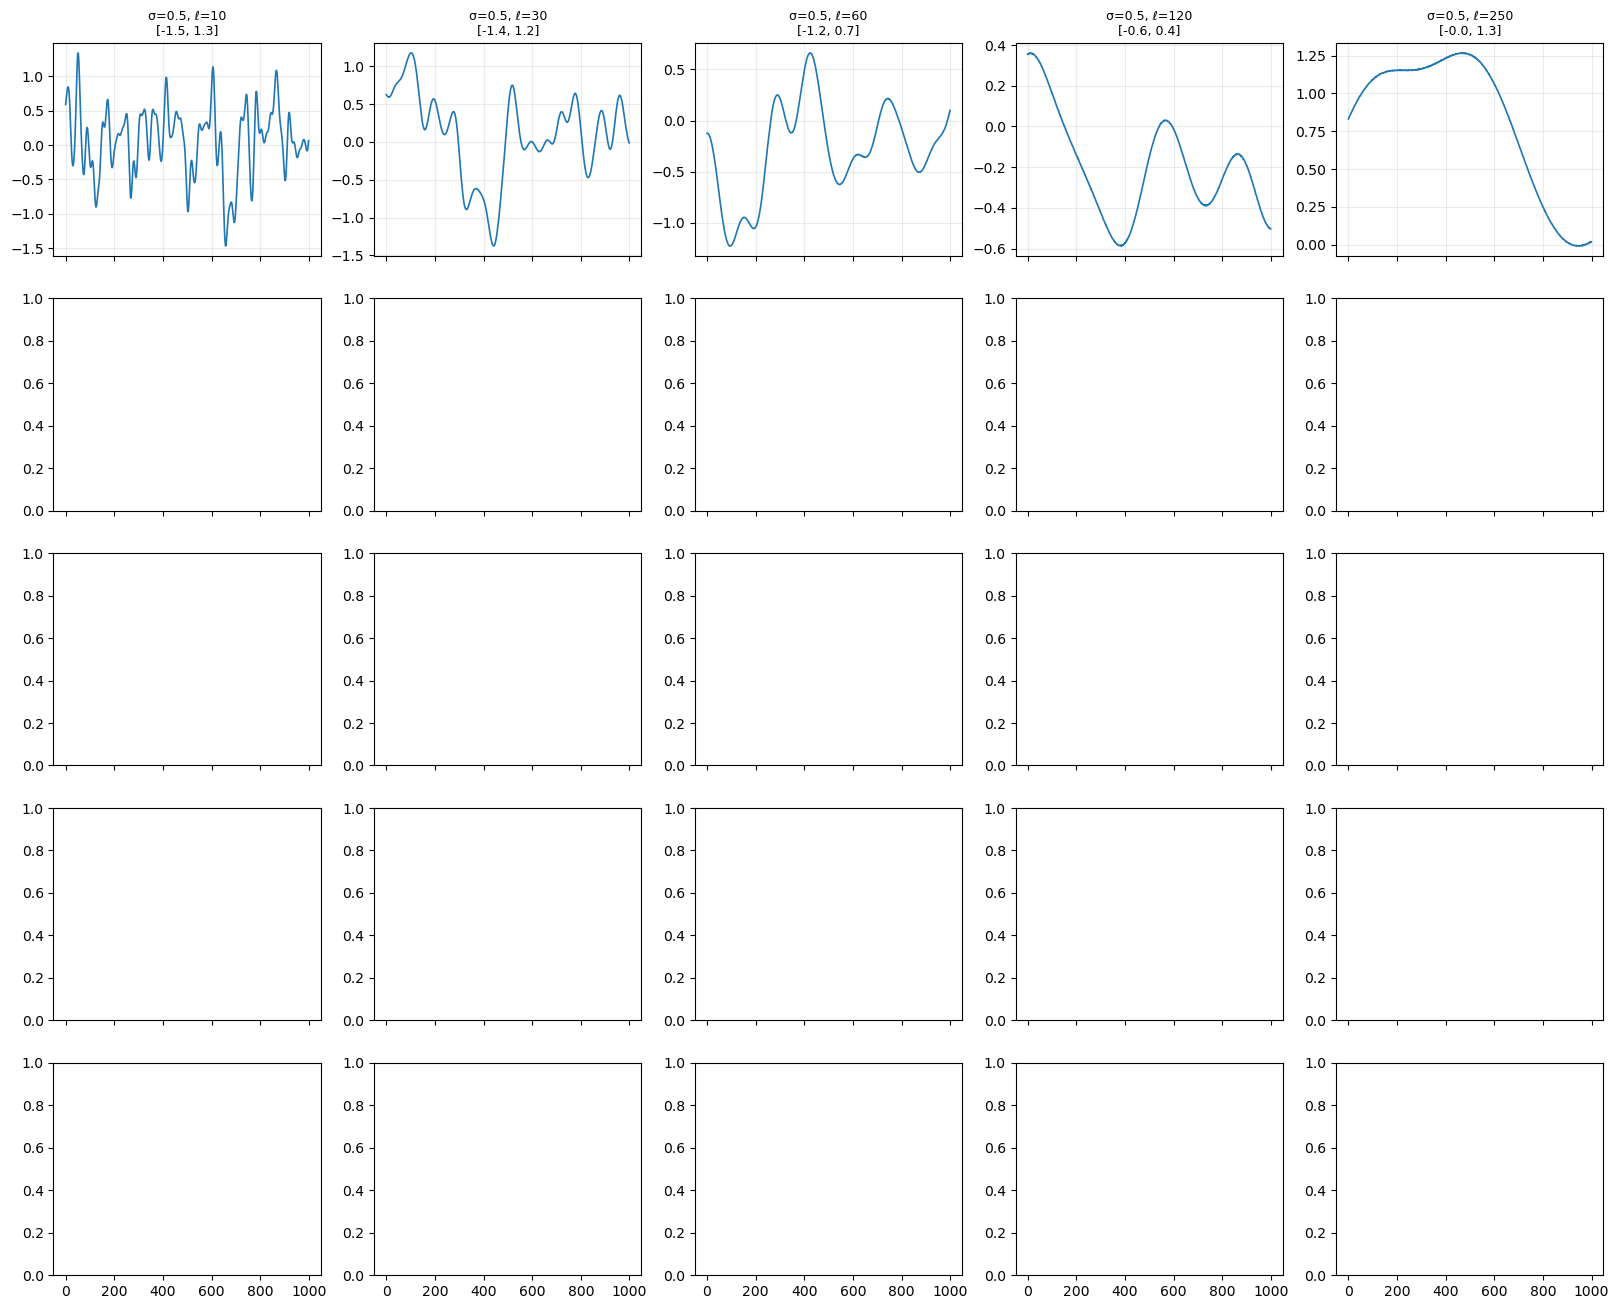

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# GP utilities
# -----------------------------
def rbf_kernel(x1, x2, sigma=1.0, length_scale=25):
    x1 = x1[:, None]
    x2 = x2[:, None]
    return sigma**2 * np.exp(
        -(x1 - x2.T)**2 / (2 * length_scale**2)
    )

def sample_gp(n=1000, sigma=1.0, length_scale=50):
    t = np.arange(n)

    K = rbf_kernel(
        t,
        t,
        sigma=sigma,
        length_scale=length_scale
    )

    K += 1e-6 * np.eye(n)

    return np.random.multivariate_normal(
        np.zeros(n),
        K
    )

# -----------------------------
# Parameter grid
# -----------------------------
sigmas = [0.5, 1, 2, 5, 10]
length_scales = [10, 30, 60, 120, 250]

n = 1000

fig, axes = plt.subplots(
    len(sigmas),
    len(length_scales),
    figsize=(20, 16),
    sharex=True
)

for i, sigma in enumerate(sigmas):
    for j, ls in enumerate(length_scales):

        g = sample_gp(
            n=n,
            sigma=sigma,
            length_scale=ls
        )

        ax = axes[i, j]
        ax.plot(g, lw=1.2)

        ymin = g.min()
        ymax = g.max()

        ax.set_title(
            f"σ={sigma}, ℓ={ls}\n"
            f"[{ymin:.1f}, {ymax:.1f}]",
            fontsize=9
        )

        ax.grid(alpha=0.25)

plt.suptitle(
    "Gaussian Process Samples (RBF Kernel)",
    fontsize=18
)

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

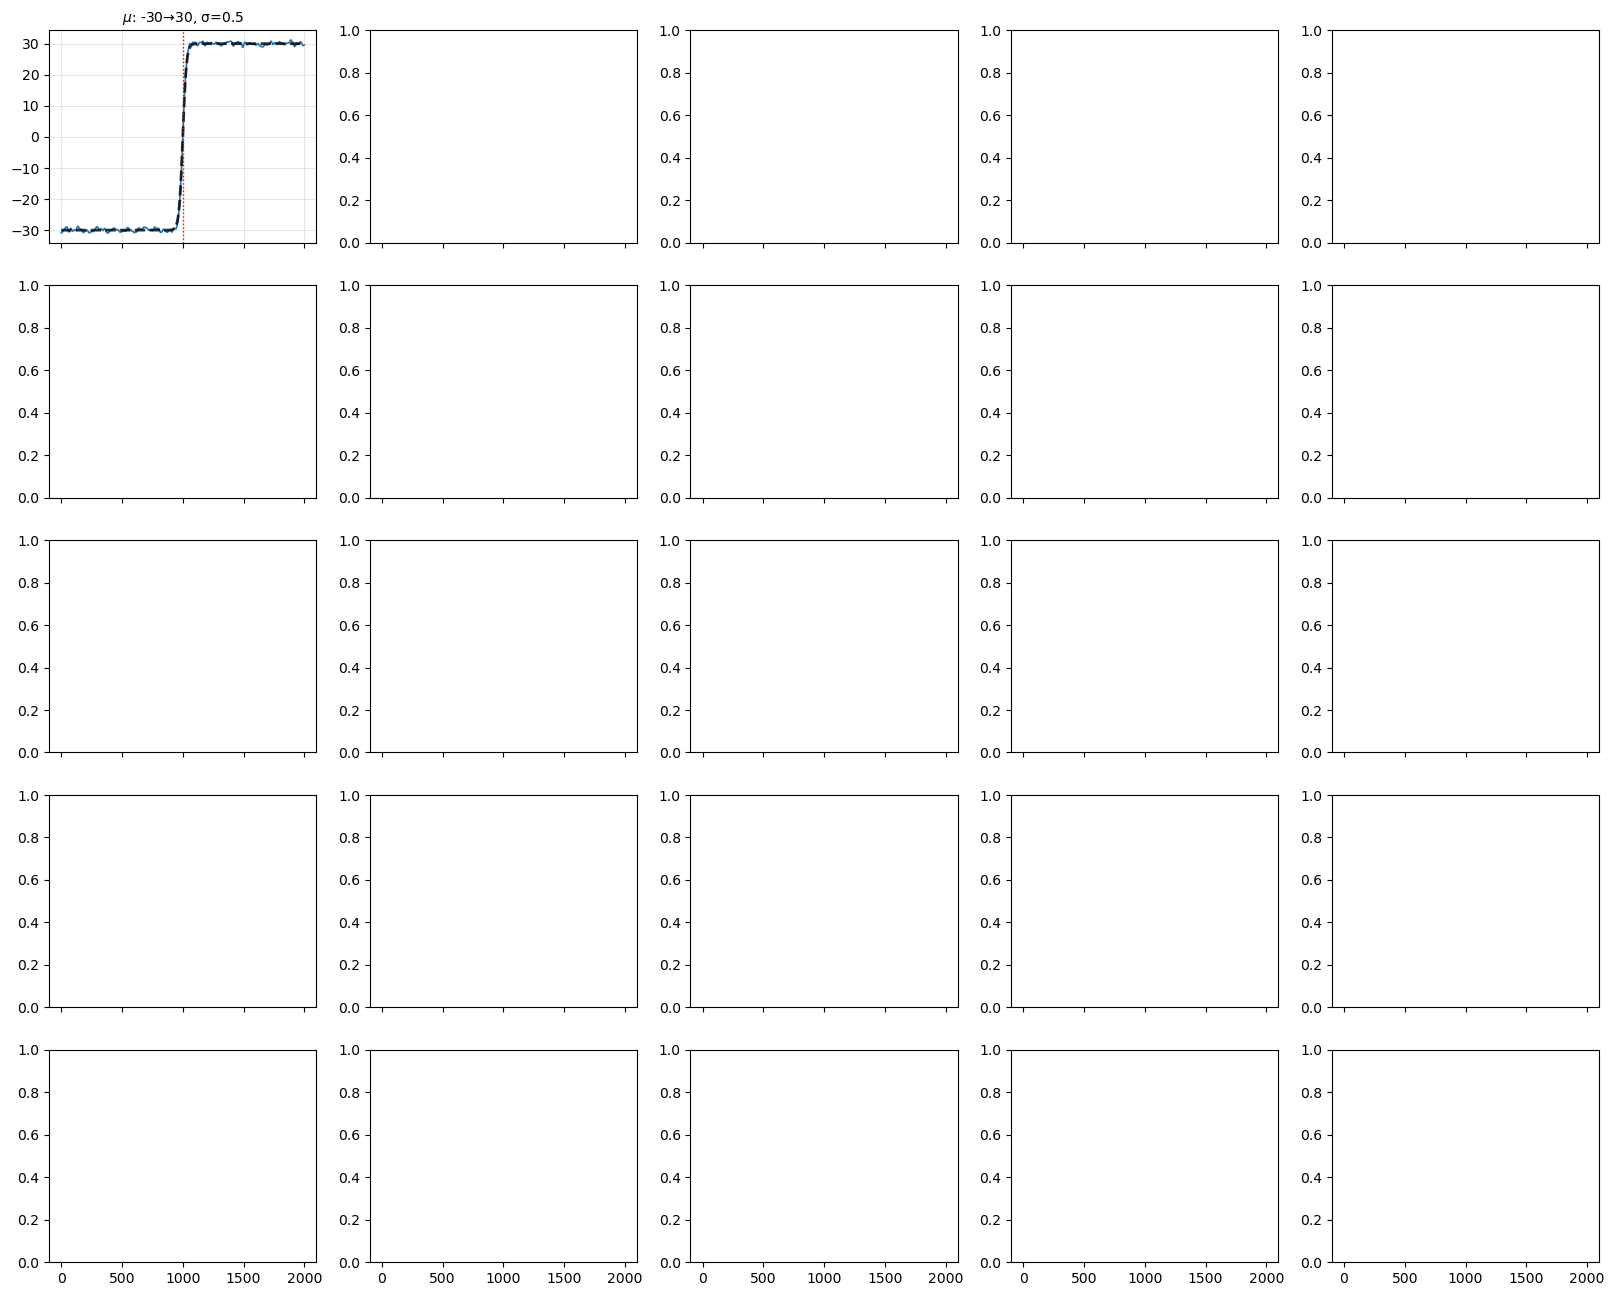

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# GP utilities
# ----------------------------
def rbf_kernel(x1, x2, sigma=1.0, length_scale=200):
    x1 = x1[:, None]
    x2 = x2[:, None]
    return sigma**2 * np.exp(
        -(x1 - x2.T)**2 / (2 * length_scale**2)
    )

def sample_gp(n, sigma=1.0, length_scale=200):
    t = np.arange(n)

    K = rbf_kernel(
        t,
        t,
        sigma=sigma,
        length_scale=length_scale
    )

    K += 1e-6 * np.eye(n)

    return np.random.multivariate_normal(
        np.zeros(n),
        K
    )

# ----------------------------
# Smooth mean transition
# ----------------------------
def smooth_mean(t, cp, mean_pre, mean_post, width=15):
    """
    Logistic transition from mean_pre to mean_post.

    width controls how gradual the transition is.
    Larger width = smoother transition.
    """
    w = 1 / (1 + np.exp(-(t - cp) / width))
    return mean_pre * (1 - w) + mean_post * w

# ----------------------------
# Parameters
# ----------------------------
n = 2000
cp = 1000
length_scale = 10

mean_shifts = [
    (-30, 30),
    (-10, 10),
    (-3, 3),
    (-1, 1),
    (0, 0)
]

sigmas = [0.5, 1, 2, 5, 10]

transition_width = 15

# ----------------------------
# Plot
# ----------------------------
fig, axes = plt.subplots(
    len(mean_shifts),
    len(sigmas),
    figsize=(20, 16),
    sharex=True
)

t = np.arange(n)

for i, (m_pre, m_post) in enumerate(mean_shifts):

    for j, sigma in enumerate(sigmas):

        gp = sample_gp(
            n=n,
            sigma=sigma,
            length_scale=length_scale
        )

        mean = smooth_mean(
            t=t,
            cp=cp,
            mean_pre=m_pre,
            mean_post=m_post,
            width=transition_width
        )

        g = gp + mean

        ax = axes[i, j]

        ax.plot(g, lw=1.2)
        ax.plot(mean, "k--", lw=2, alpha=0.8, label="Mean")

        ax.axvline(
            cp,
            color="red",
            linestyle=":",
            linewidth=1
        )

        ax.set_title(
            f"$\\mu$: {m_pre}→{m_post}, σ={sigma}",
            fontsize=10
        )

        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

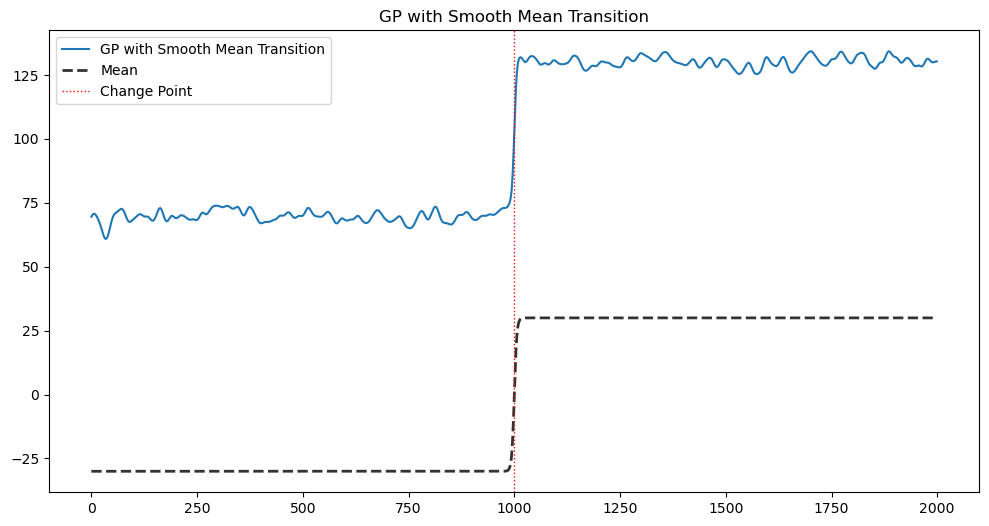

[-30.45226114 -30.15126237 -29.87803412 ...  30.33417062  30.35029752
  30.33593907]


In [8]:
# -----------------------------------
# GP parameters
# -----------------------------------
sigma = 2
length_scale = 10
n = 2000

t = np.arange(n)

K = rbf_kernel(
    t,
    t,
    sigma=sigma,
    length_scale=length_scale
)
K += 1e-6 * np.eye(n)

times = np.linspace(0, 1, n)

# -----------------------------------
# Smooth mean transition
# -----------------------------------
def smooth_mean(t, cp, mean_pre, mean_post, width=100):

    w = 1 / (1 + np.exp(-(t - cp) / width))

    return mean_pre * (1 - w) + mean_post * w

# -----------------------------------
# PRE GP
# -----------------------------------
gp_pre_vals = np.random.multivariate_normal(
    -30 * np.ones(n),
    K
)

def gp_pre(t):
    return np.interp(t, times, gp_pre_vals)

# -----------------------------------
# POST GP
# -----------------------------------
gp_post_vals = np.random.multivariate_normal(
    30 * np.ones(n),
    K
)

def gp_post(t):
    return np.interp(t, times, gp_post_vals)

# -----------------------------------
# TEST GP
# -----------------------------------
gp_zero = np.random.multivariate_normal(
    np.zeros(n),
    K
)

mean = smooth_mean(
    np.arange(n),
    cp=1000,
    mean_pre=-30,
    mean_post=30,
    width=3
)

gp_test_vals = gp_zero + mean
# Plot
plt.figure(figsize=(12, 6))
plt.plot(gp_test_vals + 100, label="GP with Smooth Mean Transition")
plt.plot(mean, "k--", lw=2, alpha=0.8, label="Mean")
plt.axvline(1000, color="red", linestyle=":", linewidth=1, label="Change Point")
plt.title("GP with Smooth Mean Transition")
plt.legend()
plt.show()

def gp_test(t):
    return np.interp(t, times, gp_test_vals)
print(gp_test_vals)


In [9]:
# ----------------------------
# Pre-change data
# ----------------------------
import numpy as np
import model.simulator
from model.simulator import SyntheticSimulator


sim_kwds = {
    'S': np.array([[0., 1.], [0., 1.]]),
    'center_post': center_post,
    'radius_post': radius_post,
    'nu': 0.5,
    'T': np.array([0., 1.]),
    'mu0': 100,
    'mu1': 100,      # keep constant
    'beta': 1.0,
    'alpha': 0.
}

sim_kwds_ = sim_kwds.copy()
sim_kwds_["nu"] = 1.0          # never enters post regime

sim = SyntheticSimulator(
    **sim_kwds_,
    gp=gp_pre
)

data_pre = sim.simulate(
    verbose=True,
    restart=False,
    lam_bar=130
)

# ----------------------------
# Post-change data
# ----------------------------
sim_kwds_ = sim_kwds.copy()
sim_kwds_["nu"] = 0.0          # always in post regime
sim_kwds_["radius_post"] = 1.0

sim = SyntheticSimulator(
    **sim_kwds_,
    gp=gp_post
)

data_post = sim.simulate(
    verbose=True,
    restart=False,
    lam_bar=170
)

# ----------------------------
# Test data
# ----------------------------
sim = SyntheticSimulator(
    **sim_kwds,
    gp=gp_test
)

data = sim.simulate(
    verbose=True,
    restart=False,
    lam_bar=170
)
# Print shape
print("Data shape:", data.shape)

Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 13380.47it/s]


lam_bar: 130, observed max lam: 74.09


Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 8716.31it/s] 


lam_bar: 170, observed max lam: 134.35


Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 18332.72it/s]

lam_bar: 170, observed max lam: 134.28
Data shape: (104, 3)


In [32]:
# write g to csv
import pandas as pd
pd.DataFrame({
    "g": g
}).to_csv("g.csv", index=False)


In [37]:
from model.score import ScoreModel

score_kwds = {
    'ndim': 3,
    'radius': radius_post,
    'ff_layers': [64],
    'rn_layers': 2,
    'rn_hidden': 64,
    'use_transform': False
}

f0 = ScoreModel(**score_kwds)
f1 = ScoreModel(**score_kwds)

In [ ]:
# First half of data

fit_kwds = {
     'data': data_pre,
     'batch_size': 256,
     'n_epochs': 400,
     'lr': 1e-3,
     'sigma': 0.1,
     'save_folder': 'cache/demo/offline/f0'
 }

f0.fit(**fit_kwds)

In [12]:
f0.load('cache/demo/offline/f0')

In [ ]:

fit_kwds = {
     'data': data_pre,
     'batch_size': 256,
     'n_epochs': 400,
     'lr': 1e-3,
     'sigma': 0.1,
     'save_folder': 'cache/demo/offline/f1'
}

f1.fit(**fit_kwds)

In [66]:
f1.load('cache/demo/offline/f1')

In [40]:
from model.detect import SpatioTemporalDetector

offline_kwds = {
    'data': data,
    'ntt': 100,
    'K': 5,
    'verbose': True,
    'nres': 20,
    'radius': 0.05,
    'use_grid': False
} 

detector = SpatioTemporalDetector(f0, f1)
tt, tau_list, omega_list, stat_list, measure = detector.offline(**offline_kwds)
print(stat_list)
print(omega_list)
print(tau_list)
print(tt)

Offline: 100%|██████████| 100/100 [00:00<00:00, 11807.96it/s]

[0, 0.16775799, 0.16775799, 0.16775799, 0.16775799, 0.16775799, 0.33377743, 0.33377743, 0.4993372, 0.4993372, 0.4993372, 0.5426283, 0.5426283, 0.5426283, 0.86961985, 0.86961985, 1.0326667, 1.0743628, 1.0743628, 1.0743628, 1.0743628, 1.2398825, 1.2398825, 1.2398825, 1.2398825, 1.2789788, 1.3211474, 1.3211474, 1.3211474, 1.6412988, 1.6788621, 1.8414841, 1.8414841, 1.885992, 1.885992, 1.885992, 1.885992, 1.9290495, 1.9290495, 1.9290495, 1.9290495, 1.9731693, 2.014439, 2.014439, 2.014439, 2.014439, 2.014439, 2.014439, 2.014439, 2.0462575, 2.0462575, 2.1086764, 2.1086764, 2.1086764, 2.1086764, 2.4192224, 2.4487119, 2.4487119, 2.6082506, 2.6082506, 2.819261, 2.847093, 2.847093, 2.847093, 3.0136647, 3.0136647, 3.0136647, 3.0136647, 3.3324647, 3.3324647, 3.3324647, 3.5232038, 3.7250528, 3.7250528, 3.8909092, 3.9274273, 4.0888515, 4.1120963, 4.3015637, 4.3756375, 4.3756375, 4.3756375, 4.3756375, 4.415475, 4.415475, 4.415475, 4.415475, 4.415475, 4.556323, 4.5849943, 4.5849943, 4.5849943, 4.62545

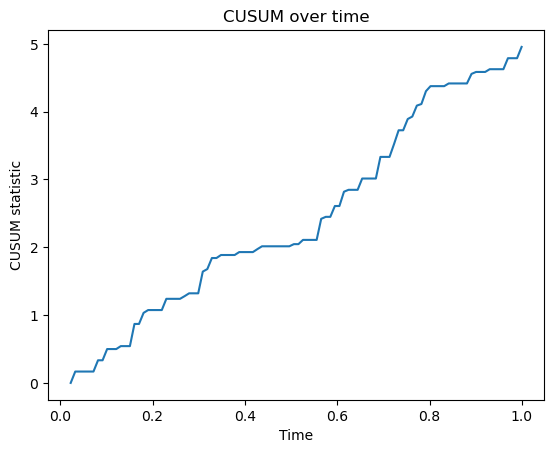

In [41]:
import matplotlib.pyplot as plt

plt.plot(tt, stat_list)
plt.xlabel("Time")
plt.ylabel("CUSUM statistic")
plt.title("CUSUM over time")
plt.show()

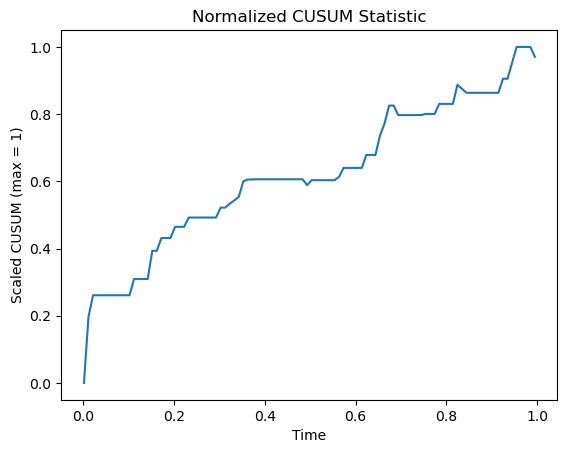

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Convert to array
stat_arr = np.array(stat_list)

# Avoid division by zero
max_val = stat_arr.max()
if max_val == 0:
    stat_scaled = stat_arr
else:
    stat_scaled = stat_arr / max_val

# Plot
plt.plot(tt, stat_scaled)
plt.xlabel("Time")
plt.ylabel("Scaled CUSUM (max = 1)")
plt.title("Normalized CUSUM Statistic")
plt.show()

In [33]:
# 1. Did f0/f1 actually converge, or are they still dominated by `base`?
print("f0.base:", f0.base.data)
print("f1.base:", f1.base.data)

# 2. Is the anomaly measure centered near 0 pre-change (as it should be)?
measure_pre = f0.psi(data_pre) - f1.psi(data_pre)
print("mean:", measure_pre.mean(), "std:", measure_pre.std())

f0.base: tensor([-2.2509,  0.0000,  0.0000])
f1.base: tensor([-5.4785,  0.0000,  0.0000])
mean: 0.03743756 std: 6.069514


In [ ]:
import numpy as np
import pandas as pd

# Convert to arrays
stat_arr = np.array(stat_list)

# Scale so max = 1 (avoid divide-by-zero)
max_val = stat_arr.max()
stat_scaled = stat_arr if max_val == 0 else stat_arr / max_val

# Create DataFrame
df = pd.DataFrame({
    "time": tt,
    "cusum": stat_arr,
    "cusum_scaled": stat_scaled
})

# Save to CSV
df.to_csv("cusum_results.csv", index=False)


print("Saved to cusum_results.csv")

Saved to cusum_results.csv


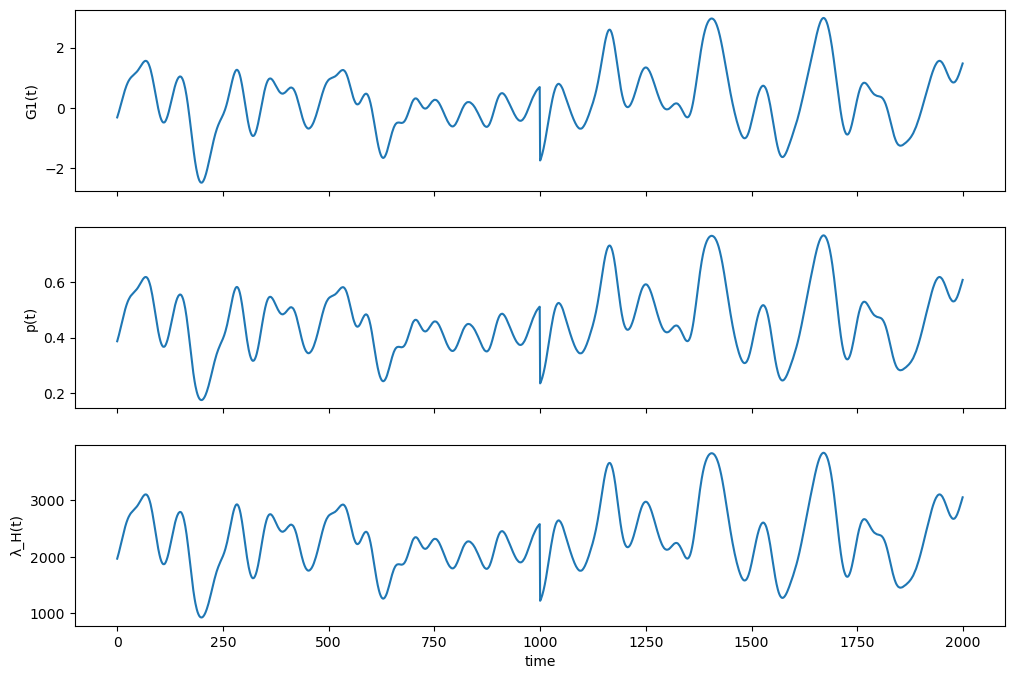

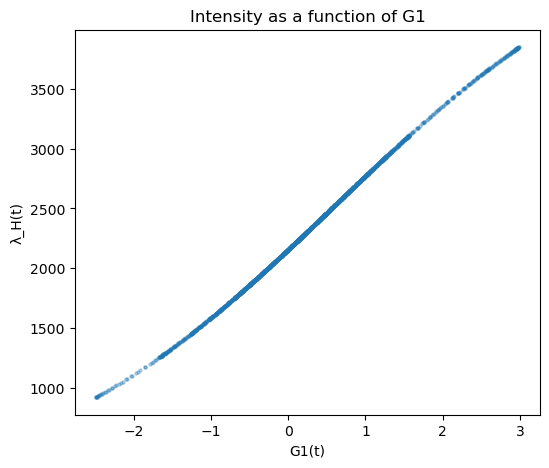

In [34]:
g_slope = sim_kwds["g_slope"]
g_threshold = sim_kwds["g_threshold"]
mu0 = sim_kwds["mu0"]
mu1 = sim_kwds["mu1"]



p = 1/(1+np.exp(
    -g_slope*(G1-g_threshold)
))

lambda_hotspot = (
    mu0 +
    (mu1-mu0)*p
)

fig, ax = plt.subplots(
    3,1,
    figsize=(12,8),
    sharex=True
)

ax[0].plot(G1)
ax[0].set_ylabel("G1(t)")

ax[1].plot(p)
ax[1].set_ylabel("p(t)")

ax[2].plot(lambda_hotspot)
ax[2].set_ylabel("λ_H(t)")
ax[2].set_xlabel("time")

plt.show()

plt.figure(figsize=(6,5))

plt.scatter(
    G1,
    lambda_hotspot,
    s=5,
    alpha=0.3
)

plt.xlabel("G1(t)")
plt.ylabel("λ_H(t)")
plt.title("Intensity as a function of G1")

plt.show()

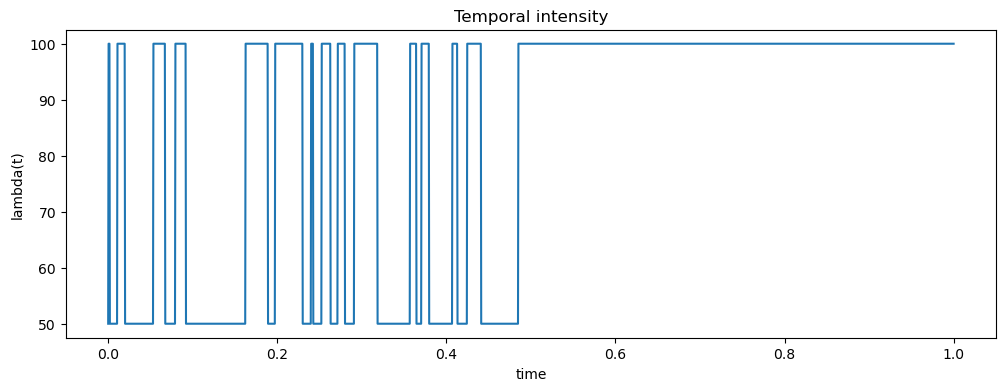

In [9]:
times = np.linspace(0, 1, len(g))

lambda_t = np.where(
    g > 0,
    sim_kwds["mu1"],
    sim_kwds["mu0"]
)

plt.figure(figsize=(12,4))
plt.plot(times, lambda_t)
plt.xlabel("time")
plt.ylabel("lambda(t)")
plt.title("Temporal intensity")
plt.show()

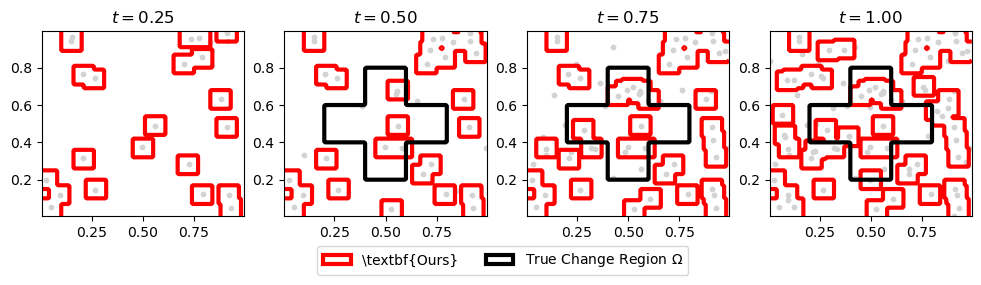

In [88]:
from utils.plot import visualize
visualize(center_list=omega_list, radius=offline_kwds['radius'], data=data, center_post=center_post, radius_post=radius_post)

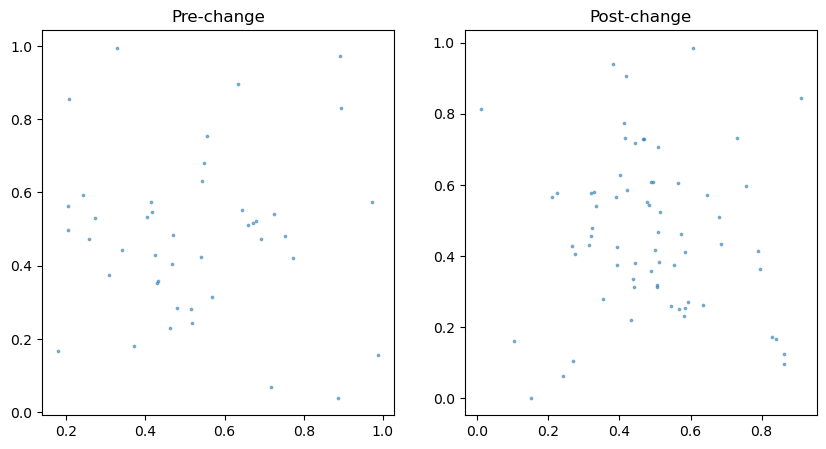

In [125]:
pre = data[data[:,0] < 0.5]
post = data[data[:,0] >= 0.5]

fig, ax = plt.subplots(1,2, figsize=(10,5))

ax[0].scatter(
    pre[:,1],
    pre[:,2],
    s=3,
    alpha=0.5
)
ax[0].set_title("Pre-change")

ax[1].scatter(
    post[:,1],
    post[:,2],
    s=3,
    alpha=0.5
)
ax[1].set_title("Post-change")

plt.show()

# Online

In [21]:
import numpy as np
from model.simulator import SyntheticSimulator

radius_post = 0.1
center_post = np.array([
    [0.5, 0.5],
    [0.5+2*radius_post, 0.5],
    [0.5-2*radius_post, 0.5],
    [0.5, 0.5-2*radius_post],
    [0.5, 0.5+2*radius_post],
])

sim_kwds = {    
    'S':            np.array([[0., 1.], [0., 1.]]),
    'center_post':  center_post,
    'radius_post':  radius_post,
    'nu':       0.5,
    'T':        np.array([0., 1.]),
    'mu0':      50,
    'mu1':      5000,
    'beta':     1.0,
    'alpha':    0.
}


# pre-change data
sim_kwds_ = sim_kwds.copy()
sim_kwds_['nu'] = 1.0
sim = SyntheticSimulator(**sim_kwds_)
data_pre = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

# test data
sim = SyntheticSimulator(**sim_kwds)
data = sim.simulate(verbose=True, restart=False, lam_bar=sim_kwds_['mu1'])   # [ nsample, 3 ]

Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 833.68it/s]


lam_bar: 5000, observed max lam: 50.00


Synthetic simulator:  99%|█████████▉| 99/100 [00:00<00:00, 493.51it/s]

lam_bar: 5000, observed max lam: 5000.00


In [8]:
from model.score import ScoreModel

score_kwds = {
    'ndim': 3,
    'radius': radius_post,
    'ff_layers': [64],
    'rn_layers': 2,
    'rn_hidden': 64,
    'use_transform': False
}

f0 = ScoreModel(**score_kwds)
f1 = ScoreModel(**score_kwds)

In [22]:
fit_kwds = {
     'data': data_pre,
     'batch_size': 256,
     'n_epochs': 100,
     'lr': 0e-3,
     'sigma': 0.1,
     'save_folder': 'cache/demo/offline/f0'
}

f0.fit(**fit_kwds)

In [12]:
from model.detect import SpatioTemporalDetector

fit_update_kwds = {
    'batch_size': 256,
    'n_epochs': 1,
    'lr': 0e-3,
    'sigma': 0.1,
}

online_kwds = {
    'data': data,
    'ntt': 100,
    'K': 5,
    'n_update': 10,
    'window': None,
    'verbose': True,
    'nres': 20,
    'fit_kwds': fit_update_kwds,
    'radius': 0.05,
    'use_grid': False
} 

detector = SpatioTemporalDetector(f0, f1)
tt, tau_list, omega_list, stat_list, measure = detector.online(**online_kwds)

Online: 100%|██████████| 100/100 [00:06<00:00, 15.43it/s]


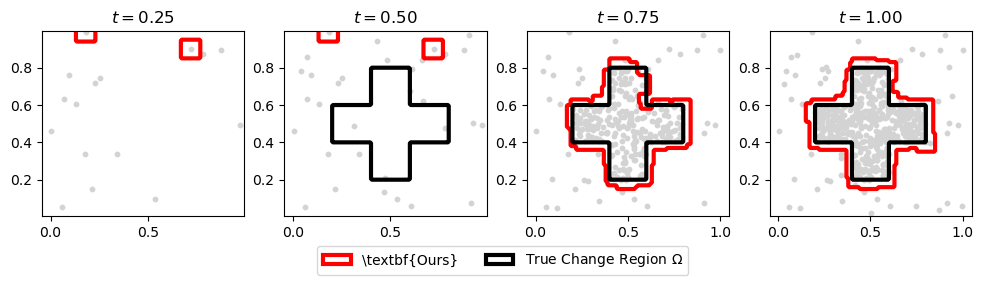

NameError: name 'results' is not defined

In [ ]:
from utils.plot import visualize
visualize(center_list=omega_list, radius=offline_kwds['radius'], data=data, center_post=center_post, radius_post=radius_post)
